# 05 — 예측 신뢰도 보정 (`results/calib_conf`)

서비스 모델 출력을 실제 비율에 맞는 확률로 바꾸는 확률표 3개를, 서비스 모델과 같은 입력 조합의 교차검증 예측으로 만든다.

| 신뢰도 | 정의 | 보정 입력 | 보정 전 | 보정 자료 |
|---|---|---|---|---|
| `conf_ess` | 필수 유전자일 확률 (`call` = `conf_ess` ≥ 0.5) | 분류 로짓 | 분류 모델 확률 | `esscls_ablation/nobio` |
| `conf_sign` | 실측 적합도가 예측과 같은 쪽(균주 평균보다 높음 / 낮음)에 있을 확률 | $(\mu,\ \log\sigma)$ | $\Phi(\lvert\mu\rvert / \sigma)$ | `fitpred_ablation/noseq` |
| `conf_fit` | 실측 적합도가 $\mu \pm \sigma$ 안에 있을 확률 | $(\mu,\ \log\sigma)$ | 0.683 | `fitpred_ablation/noseq` |

- 실측 적합도 = 균주 내 z-정규화 `fit_mean`, $\mu$ · $\sigma$ = 회귀 모델 가지 간 평균 · 표준편차 (`fitness_z` · `fitness_sd`)

| 파일 (`results/calib_conf/`) | 내용 |
|---|---|
| `calibration.json` | 확률표 3개 (격자 · 확률 · 반복 수), 서비스 `assets/` 로 복사 |
| `conf_*/fold##_<genus>/inner##/` | `model.pkl` (내부 폴드 모델) · `pred.npz` (`best_iter` · 확률표 `table` · 시험 예측 `after`, 둘 다 있으면 다시 학습하지 않고 읽는다) · `metrics_organ.csv` (균주별 보정 전 · 후 지표) · `calibration.png` · `confusion.png` (`conf_ess`) |
| `conf_*/fold##_<genus>/metrics_folds.csv` | 내부 폴드별 1줄 + mean · median · std 줄 |
| `conf_*/metrics_total.csv` | genus별 보정 전 · 후 성능 (마지막 3줄 = genus 간 mean · median · std) |
| `conf_*/model_final.pkl` | 최종 모델 (28 genus 전체) |
| `compare.csv` | 신뢰도 · 지표별 보정 전 · 후 genus 평균 ± 표준편차 |
| `check_conf_*.csv` | 확률 구간별 예측 확률 평균 · 실제 비율 (보정 전 · 후) |
| `calibration.png` | 보정 그림 (위 행 보정 전, 아래 행 보정 후) |

진행: 1 데이터 → 2 보정 대상 → 3 확률표 → 4 중첩 교차검증 → 5 보정 전 · 후 비교 → 6 최종 확률표

In [1]:
import os, json
import numpy as np, pandas as pd
from scipy.special import logit
from proteomefit import calib, data
from proteomefit.config import Config
from proteomefit.plots import reliability_plot

cfg      = Config()                                    # base data 경로
SRC_DIR  = {'ess': '../results/esscls_ablation/nobio',  # 보정 자료 (서비스 모델 입력 조합의 교차검증 결과)
            'fit': '../results/fitpred_ablation/noseq'}
OUT_DIR  = '../results/calib_conf'
GRIDS    = {'ess':  [np.round(np.arange(-10, 10.01, 0.1), 2)],                    # 로짓 격자 [201]
            'sign': [np.round(np.arange(-8, 2.01, 0.1), 2), np.round(np.arange(-1.6, 1.21, 0.1), 2)],   # mu [101] · log(sd) [29]
            'fit':  [np.round(np.arange(-8, 2.01, 0.1), 2), np.round(np.arange(-1.6, 1.21, 0.1), 2)]}
MONO     = {'ess': [1], 'sign': None, 'fit': None}      # 단조 제약 (conf_ess = 로짓에 단조 증가)
HGB      = dict(learning_rate=0.1, max_leaf_nodes=15, min_samples_leaf=1000)    # 기울기 부스팅 설정
MAX_ITER = 300                                          # 내부 폴드 반복 상한
BINS     = np.linspace(0, 1, 11)                        # 검증 표 · ECE 의 확률 구간 10개
os.makedirs(OUT_DIR, exist_ok=True)

## 1. 데이터 — 교차검증 예측과 라벨

| 표 | 형태 | 열 |
|---|---|---|
| `E` (분류) | `[586,062]` | `prob` 분류 모델 확률 · `ess` 필수 여부 · `org` · `genus` · `inner` 원 모델 내부 폴드 |
| `R` (회귀) | `[531,951]` | `mu` · `sd` · `y` 실측 (균주 내 z) · `org` · `genus` · `inner` |

- 예측 = `SRC_DIR/fold##_<genus>/inner##/pred.npz` (외부 폴드 28 x 내부 폴드 3, 유전자마다 3개)
- `VAL` = genus별 원 모델의 내부 검증 genus 3개 (`metrics_total.csv` 의 `val_genera`)

In [2]:
# 분류 - fit_mean 이 있는 샘플 [n_cls] -> 예측 표 [n_pred, 5] (prob, ess, org, genus, inner)
D = data.load_samples(cfg.base_dir, cfg.label_col, finite_only=False)
E = calib.load_cv_preds(SRC_DIR['ess'], {'ess': data.ess_labels(D), 'org': D.org}, D.gen)

# 회귀 - 적합도 수치가 있는 샘플 [n_reg] -> 예측 표 [n_pred, 6] (mu, sd, y, org, genus, inner)
D = data.load_samples(cfg.base_dir, cfg.label_col, finite_only=True)
R = calib.load_cv_preds(SRC_DIR['fit'], {'y': data.fit_labels(D), 'org': D.org}, D.gen)

VAL = {'ess': calib.val_genera(SRC_DIR['ess']), 'sign': calib.val_genera(SRC_DIR['fit']), 'fit': calib.val_genera(SRC_DIR['fit'])}
print(f"classification predictions: {len(E):,} | essential share {E.ess.mean():.3f} | genera {E.genus.nunique()}")
print(f"regression predictions:     {len(R):,} | median |mu| {R.mu.abs().median():.3f} | median sd {R.sd.median():.3f}")
print('validation genera (first fold):', {k: next(iter(v.items())) for k, v in VAL.items()})

classification predictions: 586,062 | essential share 0.092 | genera 28
regression predictions:     531,951 | median |mu| 0.456 | median sd 0.530
validation genera (first fold): {'ess': ('Pseudomonas', ['Acidovorax', 'Desulfovibrio', 'Marinobacter']), 'sign': ('Pseudomonas', ['Acidovorax', 'Desulfovibrio', 'Marinobacter']), 'fit': ('Pseudomonas', ['Acidovorax', 'Desulfovibrio', 'Marinobacter'])}


## 2. 보정 대상 — 입력 · 적중 · 보정 전 확률

| 신뢰도 | 입력 `X` | 적중 `hit` | 보정 전 `before` |
|---|---|---|---|
| `conf_ess` | $\mathrm{logit}(p)$ `[m, 1]` | 필수 유전자 | $p$ |
| `conf_sign` | $(\mu,\ \log\sigma)$ `[m, 2]` | $\mathrm{sign}(y) = \mathrm{sign}(\mu)$ | $\Phi(\lvert\mu\rvert / \sigma)$ |
| `conf_fit` | $(\mu,\ \log\sigma)$ `[m, 2]` | $\mu - \sigma \le y \le \mu + \sigma$ | 0.683 |

In [3]:
DATA = {'ess': E, 'sign': R, 'fit': R}
for name, df in DATA.items():
    X, hit, before = calib.calib_target(name, df)                      # [m, 1 | 2] · [m] · [m]
    print(f'conf_{name}: X {X.shape} | hit rate {hit.mean():.3f} | mean before {before.mean():.3f}')

conf_ess: X (586062, 1) | hit rate 0.092 | mean before 0.106
conf_sign: X (531951, 2) | hit rate 0.595 | mean before 0.792
conf_fit: X (531951, 2) | hit rate 0.538 | mean before 0.683


## 3. 확률표 — 기울기 부스팅

| 단계 | 내용 | 형태 |
|---|---|---|
| 학습 | `HistGradientBoostingClassifier` 로 입력 `X` → 적중 여부 분류 (반복 수 고정) | `[m, 1 \| 2]` |
| 확률표 | 격자 위 예측 확률 | `conf_ess` `[201]` · `conf_sign` · `conf_fit` `[101, 29]` |
| 적용 | 확률표 선형 보간 (격자 밖은 가장자리 값) | `[n]` |

- 반복 수 = 검증 genus 로그 손실이 가장 작은 반복 수 (`staged_predict_proba`)
- `conf_ess` 는 로짓에 단조 증가하도록 제약한다 (`monotonic_cst`)
- 함수 = `proteomefit/calib.py`, 지표 = `proteomefit/metrics.py`, 그림 = `proteomefit/plots.py`
- 아래 셀 = `conf_fit` 외부 폴드 1 · 내부 폴드 1 의 학습 · 반복 수 선택 · 확률표

In [4]:
# 예 - conf_fit 외부 폴드 1 · 내부 폴드 1: 26 genus 로 학습 -> 검증 genus 손실로 반복 수 선택 -> 확률표
G, vs = next(iter(VAL['fit'].items()))
X, hit, _ = calib.calib_target('fit', R)
gen   = R.genus.values
tr    = (gen != G) & (gen != vs[0])
model = calib.fit_hgb(X[tr], hit[tr], MAX_ITER, MONO['fit'], HGB)
b     = calib.best_iter(model, X[gen == vs[0]], hit[gen == vs[0]])
T     = calib.staged_tables(model, GRIDS['fit'])                       # 반복 수별 확률표 [300, 101, 29]
x     = np.array([[-1.0, np.log(0.5)]])                                 # mu = -1.0, sd = 0.5
print(f'test {G} | val {vs[0]} | best iteration {b} | tables {T.shape}')
print('conf_fit(mu=-1.0, sd=0.5) at iteration 1 / best / 300:',
      [round(float(calib.lookup(T[i], GRIDS['fit'], x)[0]), 3) for i in (0, b - 1, MAX_ITER - 1)])

test Pseudomonas | val Acidovorax | best iteration 35 | tables (300, 101, 29)
conf_fit(mu=-1.0, sd=0.5) at iteration 1 / best / 300: [0.519, 0.186, 0.132]


## 4. 중첩 교차검증

| 단계 | 학습 | 검증 | 시험 |
|---|---|---|---|
| 외부 폴드 $k$ (28) | — | — | genus $k$ 의 예측 |
| 내부 폴드 $j$ (3) | $k$ · $v_j$ 를 뺀 26 genus 의 예측 | 원 모델 내부 폴드 $j$ 의 검증 genus $v_j$ → 최적 반복 수 $b_{kj}$ | $b_{kj}$ 의 확률표를 genus $k$ 의 원 모델 내부 폴드 $j$ 예측에 적용 |
| 최종 | 28 genus 전체 | — | 반복 수 = $\mathrm{median}_k\ \mathrm{median}_j\ b_{kj}$ |

- genus 성능 = 내부 폴드 3개 지표의 평균 · 표준편차, 내부 폴드 지표 = 균주별 지표의 평균 (`conf_ess` 는 양 · 음성이 모두 있는 균주만)

| 지표 | 내용 | 좋은 방향 |
|---|---|---|
| `ece` | 확률 구간 10개의 \|예측 확률 평균 − 실제 비율\| 구간 크기 가중 평균 | 0 |
| `brier` | $(p - \text{적중})^2$ 의 평균 | 0 |
| `log_loss` | $-\log$ (실제 결과에 준 확률) 의 평균 | 0 |
| `roc_auc` | 적중 · 빗나감의 확률 순위 구별력 | 1 |
| `mcc` · `f1` · `recall` · `precision` · `accuracy` · `pr_auc` | `conf_ess` ≥ 0.5 판정의 분류 성능 | 1 |

In [5]:
RES, CHECK = {}, {}                                                    # genus별 결과 [28, *] · 확률 구간별 표
for name in ('ess', 'sign', 'fit'):
    RES[name], CHECK[name] = calib.nested_cv(name, DATA[name], VAL[name], GRIDS[name], MONO[name], HGB, MAX_ITER, BINS,
                                             f'{OUT_DIR}/conf_{name}')
    print()

conf_ess fold  1 Pseudomonas      best@217.0 | ece 0.044 -> 0.030 | brier 0.039 -> 0.032
conf_ess fold  2 Ralstonia        best@150.0 | ece 0.026 -> 0.019 | brier 0.034 -> 0.034
conf_ess fold  3 Shewanella       best@238.0 | ece 0.036 -> 0.012 | brier 0.040 -> 0.032
conf_ess fold  4 Dickeya          best@197.0 | ece 0.029 -> 0.009 | brier 0.035 -> 0.031
conf_ess fold  5 Cupriavidus      best@176.0 | ece 0.024 -> 0.009 | brier 0.026 -> 0.022
conf_ess fold  6 Desulfovibrio    best@233.0 | ece 0.056 -> 0.045 | brier 0.069 -> 0.068
conf_ess fold  7 Burkholderia     best@ 30.0 | ece 0.038 -> 0.018 | brier 0.041 -> 0.038
conf_ess fold  8 Sinorhizobium    best@225.0 | ece 0.040 -> 0.022 | brier 0.049 -> 0.046
conf_ess fold  9 Paraburkholderia best@ 31.0 | ece nan -> nan | brier nan -> nan
conf_ess fold 10 Klebsiella       best@ 31.0 | ece 0.031 -> 0.013 | brier 0.032 -> 0.026
conf_ess fold 11 Pedobacter       best@233.0 | ece 0.049 -> 0.043 | brier 0.039 -> 0.038
conf_ess fold 12 Azospirillum

## 5. 보정 전 · 후 비교

- `compare.csv` = 신뢰도 · 지표별 genus 28개 값의 평균 · 표준편차 (NaN genus 제외). 최종 성능 = 보정 후 평균
- `check_conf_*.csv` = 시험 예측 전체를 확률 구간으로 나눈 표

| 열 | 내용 |
|---|---|
| `stage` | `before` (보정 전) · `after` (보정 후) |
| `bin` | 그 단계 확률의 구간 |
| `n` | 구간 안 예측 수 |
| `predicted` · `observed` | 구간 안 확률 평균 · 실제 적중 비율 |

- 그림 = 위 행 보정 전, 아래 행 보정 후, 구간마다 원 하나 (가로 = 실제 비율, 세로 = 예측 확률, 넓이 = 예측 수). 대각선 위 = 보정이 맞음

     conf    metric  before  before_sd  after  after_sd
 conf_ess       ece   0.044      0.023  0.024     0.029
 conf_ess     brier   0.048      0.025  0.044     0.027
 conf_ess  log_loss   0.223      0.127  0.168     0.099
 conf_ess   roc_auc   0.934      0.040  0.934     0.041
 conf_ess       mcc   0.714      0.080  0.713     0.090
 conf_ess        f1   0.740      0.080  0.726     0.102
 conf_ess    recall   0.747      0.124  0.645     0.131
 conf_ess precision   0.752      0.047  0.861     0.033
 conf_ess  accuracy   0.942      0.028  0.947     0.032
 conf_ess    pr_auc   0.810      0.073  0.806     0.073
conf_sign       ece   0.190      0.049  0.061     0.038
conf_sign     brier   0.284      0.032  0.229     0.016
conf_sign  log_loss   0.919      0.128  0.650     0.034
conf_sign   roc_auc   0.554      0.025  0.622     0.063
 conf_fit       ece   0.140      0.062  0.067     0.033
 conf_fit     brier   0.265      0.026  0.211     0.019
 conf_fit  log_loss   0.726      0.055  0.610   

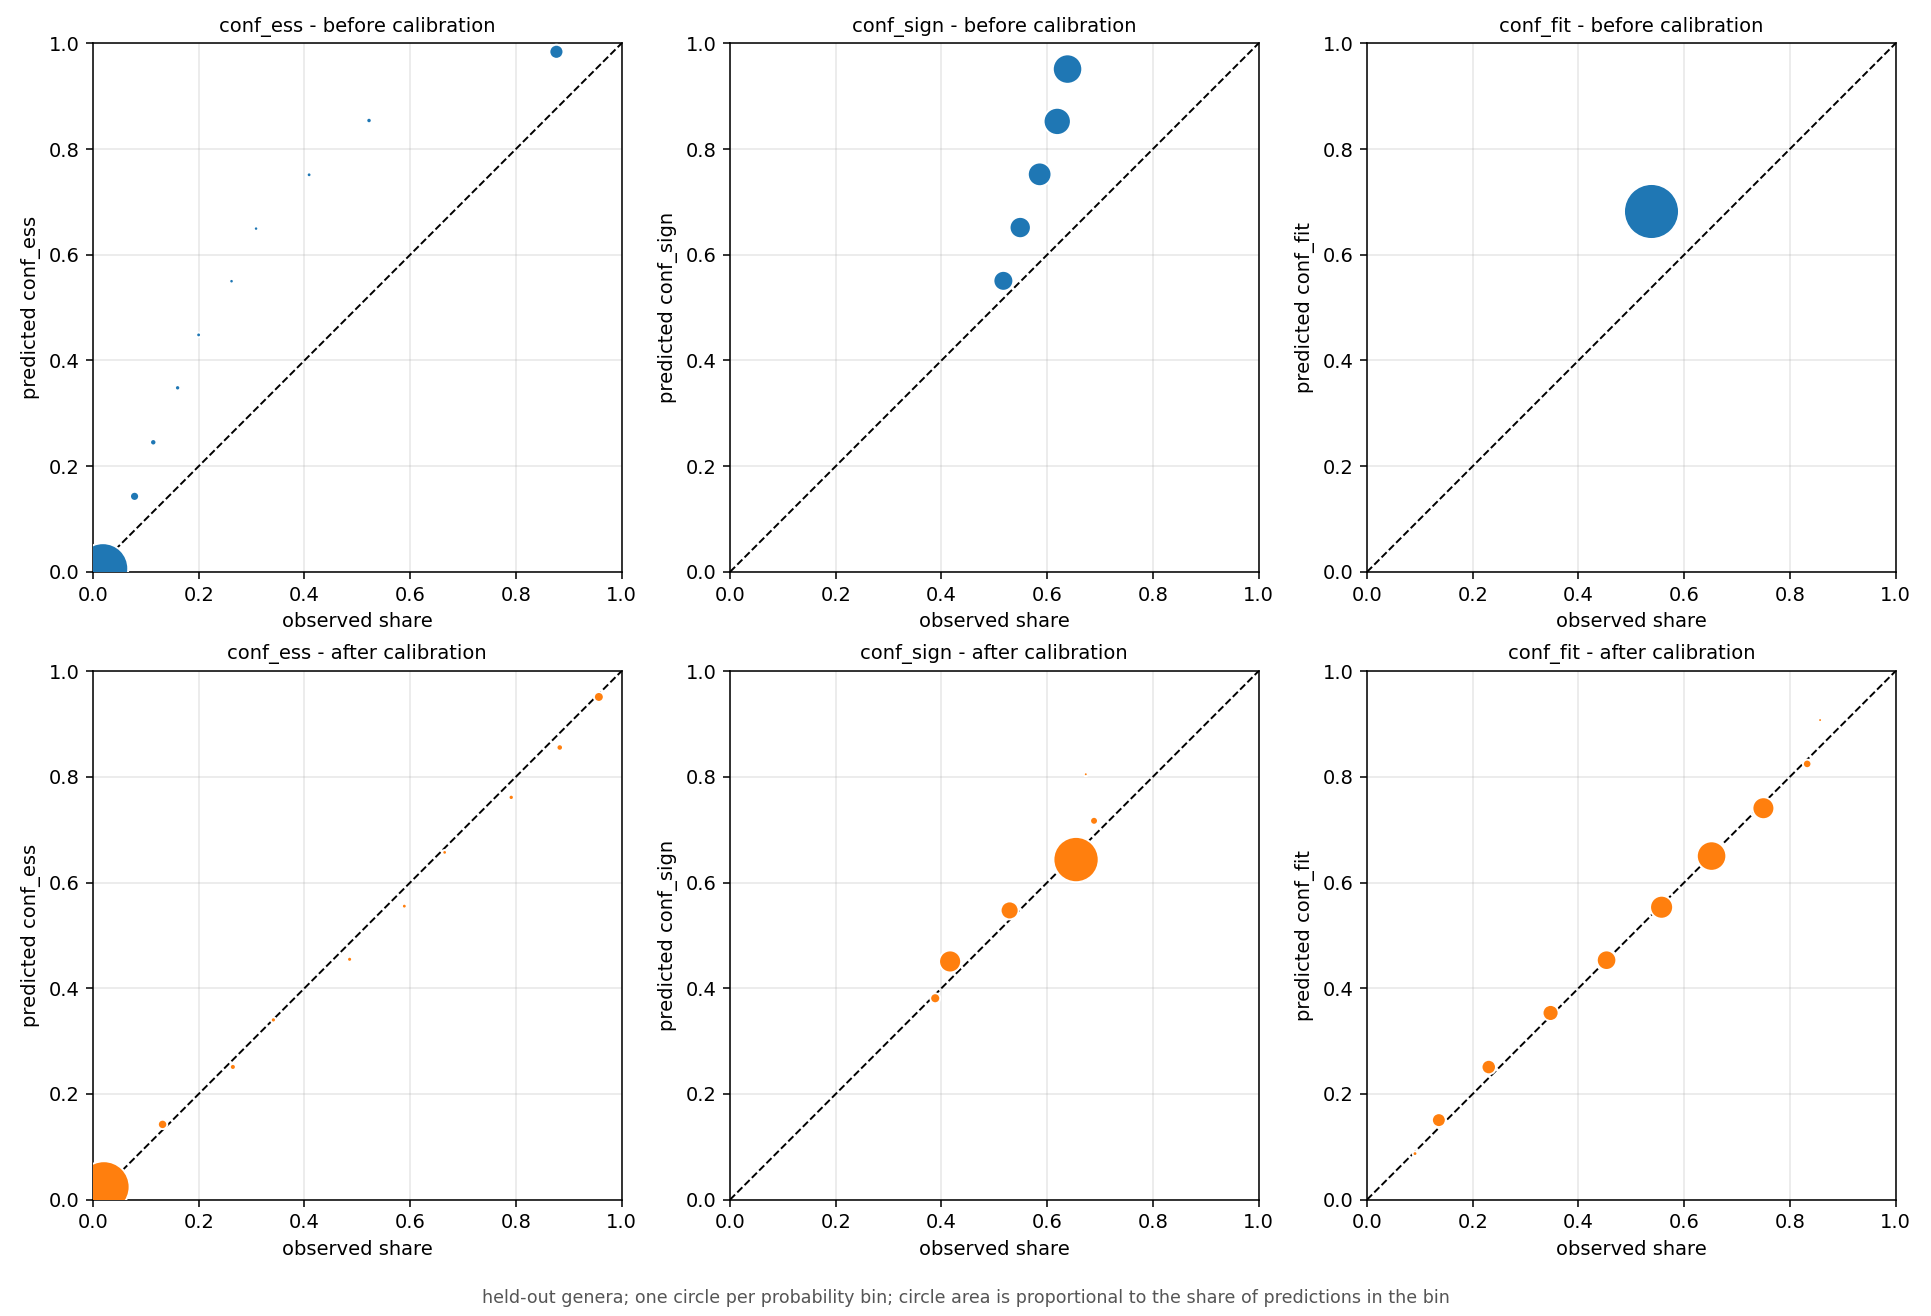

In [6]:
# 보정 전 · 후 genus 평균 · 표준편차 [지표 수, 6]
cmp = pd.DataFrame([dict(conf=f'conf_{n}', metric=c[:-7], before=r[c].mean(), before_sd=r[c].std(),
                         after=r[c[:-7] + '_after'].mean(), after_sd=r[c[:-7] + '_after'].std())
                    for n, r in RES.items() for c in r.columns if c.endswith('_before')])
cmp.round(4).to_csv(f'{OUT_DIR}/compare.csv', index=False)
print(cmp.round(3).to_string(index=False), '\n')

for name, T in CHECK.items():                                          # 확률 구간별 표 [구간 수 x 2, 5]
    T.round(4).to_csv(f'{OUT_DIR}/check_conf_{name}.csv', index=False)
    print(f'conf_{name}'); print(T.round(3).to_string(index=False), '\n')
reliability_plot({f'conf_{n}': T for n, T in CHECK.items()}, f'{OUT_DIR}/calibration.png')

## 6. 최종 확률표

28 genus 전체 예측으로 최종 모델(`conf_*/model_final.pkl`)을 학습하고, 그 확률표를 `calibration.json` 에 저장한다.

| 키 | 내용 |
|---|---|
| `ess` · `sign` · `fit` | `axes` (격자 축 목록) · `p` (확률표) · `n_iter` (반복 수) · `source` (보정 자료) |

In [7]:
cal = {}
for name, df in DATA.items():
    n_iter = int(RES[name].best_iter_med.median() + 0.5)               # genus별 최적 반복 수 중앙값의 중앙값
    table  = calib.final_model(name, df, GRIDS[name], MONO[name], HGB, n_iter, f'{OUT_DIR}/conf_{name}')
    cal[name] = dict(axes=[a.tolist() for a in GRIDS[name]], p=table.round(4).tolist(), n_iter=n_iter,
                     source=SRC_DIR['ess' if name == 'ess' else 'fit'].split('results/')[1])
    print(f'conf_{name}: final iterations {n_iter} | table {table.shape} | range {table.min():.3f} - {table.max():.3f}')
with open(f'{OUT_DIR}/calibration.json', 'w', encoding='utf-8') as f:
    json.dump(cal, f)

# 예시 - 분류 모델 확률별 conf_ess, 예측 평균 · 표준편차별 conf_sign · conf_fit
tab = lambda n: (np.array(cal[n]['p']), [np.array(a) for a in cal[n]['axes']])
ex  = pd.DataFrame({'p_model': [0.05, 0.3, 0.5, 0.7, 0.9, 0.99]})
ex['conf_ess'] = calib.lookup(*tab('ess'), logit(ex.p_model.values)[:, None])
print(ex.round(3).to_string(index=False), '\n')
ex  = pd.DataFrame({'mu': [0.1, 0.6, -0.5, -1.0, -2.0, -4.0], 'sd': [0.5, 0.4, 0.5, 0.5, 0.6, 1.0]})
for n in ('sign', 'fit'):
    ex[f'conf_{n}'] = calib.lookup(*tab(n), np.column_stack([ex.mu, np.log(ex.sd)]))
print(ex.round(2).to_string(index=False))
print(f'\nsaved {OUT_DIR}/calibration.json | conf_*/metrics_total.csv · model_final.pkl | compare.csv | check_conf_*.csv | calibration.png')

conf_ess: final iterations 210 | table (201,) | range 0.007 - 0.981
conf_sign: final iterations 18 | table (101, 29) | range 0.394 - 0.736
conf_fit: final iterations 64 | table (101, 29) | range 0.067 - 0.899
 p_model  conf_ess
    0.05     0.054
    0.30     0.148
    0.50     0.246
    0.70     0.333
    0.90     0.613
    0.99     0.888 

  mu  sd  conf_sign  conf_fit
 0.1 0.5       0.63      0.70
 0.6 0.4       0.65      0.42
-0.5 0.5       0.43      0.32
-1.0 0.5       0.48      0.14
-2.0 0.6       0.58      0.09
-4.0 1.0       0.66      0.11

saved ../results/calib_conf/calibration.json | conf_*/metrics_total.csv · model_final.pkl | compare.csv | check_conf_*.csv | calibration.png
